# MSD_15to1_main — Litinski方式：15-to-1 magic state distillation の資源計数

**目的**：Litinski *A Game of Surface Codes* [Lit] Sec. 3 の 15-to-1 プロトコル（Fig. 15 の回路を Fig. 17c の 11 tiles 配置で実行）を、
1. **tile モデル**（[Lit] の計数：1 tile = $d^2$ データ量子ビット（測定量子ビット込みで $2d^2$）、1 time step (τ) = $d$ code cycles）、
2. **物理モデル**（11 回の多パッチ測定 $P\otimes Z_m$ を Fig. 17c の配置上で**検査レベルまで明示的に構成**し（正しさは検証ノート M9）、各回転の量子ビット数・CNOT 数・ラウンドの物理時間（D4 側と同じスケジューラ）を数える。$Z_m\otimes Y_0$ の twist 継ぎ目の検査だけは構成していない）
の2通りで計数する。正しさの検証は `MSD_15to1_validation.ipynb`。

**15-to-1 の抽象回路（Reed–Muller 符号上の回路）だけを数えて lattice surgery の物理コストと同一視することはしない**：ここで数えるのは Fig. 17c の配置上の操作である。

### 段階（Fig. 17c）
| 段階 | 内容 | 時間 | 出所 |
|---|---|---|---|
| L0 | （比較Bのみ）qubits 1–4 への $|m\rangle$ 注入（並列） | $t_{\rm inj}$ | [Lit] App. A（Li の方法、3+3 cycles、$d$ に依存しない） |
| L1 | qubit 5 を $|+\rangle$ に初期化 | 0τ | [Lit] Sec. 1 |
| L2.k | auto-corrected π/8 回転 k（k=1..11）：$P\otimes Z_m$ と $Z_m\otimes Y_0$ の格子手術 | 1τ = $d$ ラウンド | [Lit] Fig. 17b,c |
| L2.ka | （比較Bのみ）回転 k 用の $|m\rangle$ 注入（11-tile 配置では直列） | $t_{\rm inj}$ | [Lit] Sec. 3.3 "Caveat" |
| L2.kb | $|0\rangle$ の X/Z 測定、$|m\rangle$ の X 測定 | 0τ（測定1層） | [Lit] |
| L3 | qubits 1–4 の X 測定 | 0τ | [Lit] |
| L4 | 論理 $\bar X$（Pauli フレーム）で $T^\dagger|+\rangle\to T|+\rangle$ | 0 | 本研究（D4 側と同じ扱い） |

**比較A**：入力 $|m\rangle$ は供給済み（L0, L2.ka を含めない）。**比較B**：注入時間と物理 T ゲート（15個）を含める。古典処理時間は両比較とも 0（**仮定**）。

In [1]:
# ==== 環境設定（Google Colab / ローカル共通）====
import os, sys, subprocess, json
IN_COLAB = 'google.colab' in sys.modules
# Colab では、すべての .ipynb を同じフォルダに置き、そのフォルダを作業ディレクトリにしてください。
# 例（Google Drive を使う場合）:
#   from google.colab import drive; drive.mount('/content/drive')
#   os.chdir('/content/drive/MyDrive/D4_vs_MSD')
for _f in ['common_lib.ipynb', 'd4_lib.ipynb', 'msd_lib.ipynb']:
    if not os.path.exists(_f):
        print(f'WARNING: {_f} が作業ディレクトリ {os.getcwd()} にありません')
RESULTS, FIGURES = 'results', 'figures'
os.makedirs(RESULTS, exist_ok=True); os.makedirs(FIGURES, exist_ok=True)
SEED = 20261024
print('cwd =', os.getcwd(), '| Colab =', IN_COLAB)

cwd = /home/user/2026-10-24_StudyWithClaude | Colab = False


In [2]:
# ==== 外部ライブラリ（Colab に無いものだけをインストール）====
import importlib
for _mod, _pkg in [('stim', 'stim'), ('scipy', 'scipy'), ('sympy', 'sympy'), ('pandas', 'pandas'),
                   ('matplotlib', 'matplotlib'), ('nbformat', 'nbformat')]:
    if importlib.util.find_spec(_mod) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', _pkg], check=True)
import numpy as np, pandas as pd, scipy
print('numpy', np.__version__, '| scipy', scipy.__version__, '| pandas', pd.__version__)

numpy 2.5.3 | scipy 1.18.1 | pandas 3.0.5


In [3]:
# ==== 図のスタイル（明るい背景・細い線・識別は色＋線種＋マーカー）====
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
                     'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b', 'text.color': '#0b0b0b',
                     'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.grid': True,
                     'grid.color': '#e4e3df', 'grid.linewidth': 0.8, 'lines.linewidth': 2,
                     'lines.markersize': 7, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 10, 'legend.frameon': False})
C_KOB, C_LIT, C_AUX = '#2a78d6', '#eb6834', '#1baf7a'     # categorical slots 1,2,3 (validated palette)
C_R, C_G, C_B = '#e34948', '#008300', '#2a78d6'            # colours of the r, g, b qubit species

In [4]:
%run -i ./common_lib.ipynb
%run -i ./msd_lib.ipynb

In [5]:
QUICK = False
D_LIST = [3, 5, 7, 9, 11, 13, 15] if not QUICK else [3, 5, 7]
DUR = dict(DUR_UNIT)
PARAMS = dict(DEFAULT_PARAMS)
print(PARAMS)

{'kappa0': 1.0, 'kappa_in': 1.0, 'kappa_out': 1.0, 'tau_rounds': 1.0, 't_inj_FT': 6, 't_inj_NL': 1}


## 1. 論理回路（式(1) → Fig. 15）
式(1)の行列 $M$ の列ごとに $Z$ 型 π/8 回転を置く。1列目〜4列目（重み1）は qubits 4,3,2,1 の初期状態 $|m\rangle$ に吸収され、残り 11 列が Fig. 15 の 11 回転になる（[Lit] Sec. 3.1）。

In [6]:
rots = fig15_rotations()
pd.DataFrame([{'rotation': k + 1, **{f'q{i + 1}': ('Z' if i in r else '1') for i in range(5)}} for k, r in enumerate(rots)])

,rotation,q1,q2,q3,q4,q5
0,1,1,1,Z,Z,Z
1,2,1,Z,1,Z,Z
2,3,1,Z,Z,1,Z
3,4,1,Z,Z,Z,1
4,5,Z,1,1,Z,Z
5,6,Z,1,Z,1,Z
6,7,Z,1,Z,Z,1
7,8,Z,Z,1,1,Z
8,9,Z,Z,1,Z,1
9,10,Z,Z,Z,1,1


## 2. tile モデル（Fig. 17c の再計数）
配置を 3×5 の格子として転記した（`FIG17C_*`）。灰色の未使用 tile は数えない。

tiles used = 11, time steps = 11 tau, tile*tau = 121
leading-order space-time cost: 121 d^3 (data qubits x cycles; [Lit] 121 d^3) / 242 d^3 (incl. measurement qubits, 2d^2 per tile, [Lit] Sec. 4.3)


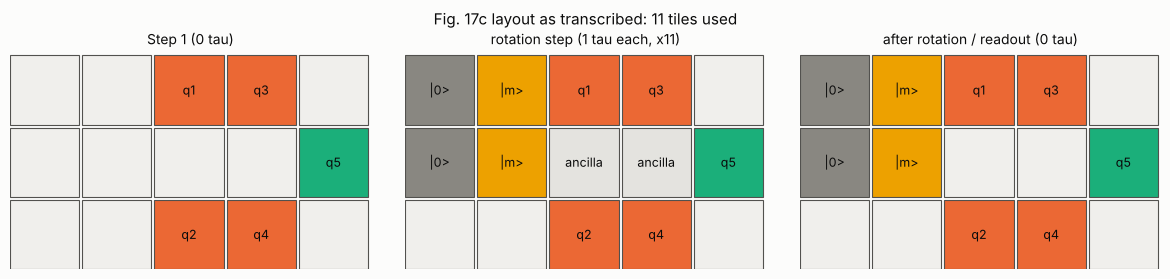

In [7]:
sched = tile_schedule()
used = tiles_used(sched)
n_tiles = len(used); n_tau = sum(t for _, t, _ in sched)
print(f'tiles used = {n_tiles}, time steps = {n_tau} tau, tile*tau = {n_tiles * n_tau}')
print(f'leading-order space-time cost: {n_tiles * n_tau} d^3 (data qubits x cycles; [Lit] 121 d^3)'
      f' / {2 * n_tiles * n_tau} d^3 (incl. measurement qubits, 2d^2 per tile, [Lit] Sec. 4.3)')
fig, axes = plt.subplots(1, 3, figsize=(12, 2.8))
colors = {'q1': C_LIT, 'q2': C_LIT, 'q3': C_LIT, 'q4': C_LIT, 'q5': C_AUX, 'm': '#eda100', 'zero': '#898781', 'anc': '#e4e3df'}
for ax, (title, lay) in zip(axes, [('Step 1 (0 tau)', FIG17C_STEP1), ('rotation step (1 tau each, x11)', FIG17C_ROTATION),
                                   ('after rotation / readout (0 tau)', FIG17C_FINAL)]):
    for i, row in enumerate(lay):
        for j, lab in enumerate(row):
            fc = colors.get(lab, '#fcfcfb') if lab else '#f0efec'
            ax.add_patch(plt.Rectangle((j, 2 - i), 0.96, 0.96, fc=fc, ec='#52514e', lw=0.8))
            if lab: ax.text(j + 0.48, 2 - i + 0.48, {'zero': '|0>', 'm': '|m>', 'anc': 'ancilla'}.get(lab, lab), ha='center', va='center', fontsize=9)
    ax.set_xlim(0, 5); ax.set_ylim(0, 3); ax.set_aspect('equal'); ax.axis('off'); ax.set_title(title, fontsize=10)
plt.suptitle(f'Fig. 17c layout as transcribed: {n_tiles} tiles used', fontsize=11)
plt.tight_layout(); plt.savefig(f'{FIGURES}/msd_fig17c_layout.png', dpi=150); plt.show()

## 3. tile → 物理量子ビット・cycle への対応

| 量 | tile モデル | 物理モデル（本研究、明示的構成） |
|---|---|---|
| 1 tile | $d^2$ データ（[Lit] Sec. 1）、$2d^2$ 測定込み（[Lit] Sec. 4.3） | $d\times d$ データ量子ビットの領域 |
| qubits 1–5 | 1 tile ずつ | 回転表面符号パッチ。補助帯に面する辺を「$Z$ 辺」（重み2 の $X$ 検査）にする |
| $|m\rangle$ | 2 tiles | 2 tile の縦長パッチ。角を移動（[Lit] Fig. 2b）し、右辺下半分（補助帯側）と左辺（$|0\rangle$ 側）を $Z$ 辺にする |
| $|0\rangle$ | 2 tiles | 縦長の回転表面符号パッチ |
| 補助帯 | 2 tiles | 全量子ビットを $|+\rangle$ に初期化し、補助帯に触れる plaquette（合併領域に制限）を新たに測る。参加しないパッチに面する辺・自由辺は「$X$ 辺」（重み2 の $Z$ 検査）、両側が自由な角の量子ビットは $Z$ 測定 |
| 合併中に測る検査 | — | 新しい検査 $N$ ＋ $N$ と可換な旧パッチ検査 ＋ 可換部分群を完成させる旧検査の積（すべて重み ≤ 4、$\mathbb F_2$ 計算で決定） |
| 1τ | $d$ code cycles | $d$ ラウンド（`FT_ref`）／1 ラウンド（`NL_min`） |
| 1 ラウンドの物理時間 | — | 各回転の検査集合を D4 側と同じ可換クラス・スケジューラで計算（下界・上界） |

**構成していない部分**：$|m\rangle$ と $|0\rangle$ の間の $Z_m\otimes Y_0$ 測定（twist 欠陥を含む継ぎ目、$O(d)$ 個の測定量子ビット）。`source` 列と比較ノートの「未計上コスト」に明記する。

In [8]:
records, summaries = [], []
for d in D_LIST:
    md_ = MSDCostData(d, DUR)
    for level in ['tile', 'physical']:
        for data_only in [False, True]:
            for model in ['FT_ref', 'NL_min']:
                for comp in ['A', 'B']:
                    st = msd_stages(md_, model, PARAMS, comp, level=level, data_only=data_only)
                    for gs in ['primitive', 'clifford_t']:      # Litinski uses only Clifford + T (injection)
                        rows_ = [dict(r, level=level, gateset=gs, data_only=data_only) for r in st]
                        records += rows_
                        s = summarize(st)
                        s.update(protocol='Litinski_15to1', d=d, model=model, comparison=comp, level=level,
                                 gateset=gs, data_only=data_only)
                        summaries.append(s)
stage_df = pd.DataFrame(records)
stage_df['gates'] = stage_df['gates'].apply(lambda g: json.dumps({k: float(v) for k, v in g.items()}))
stage_df.to_csv(f'{RESULTS}/msd_stage_costs.csv', index=False)
sum_df = pd.DataFrame(summaries)
for col in ['gates', 'nonclifford']:
    sum_df[col] = sum_df[col].apply(lambda g: json.dumps({k: float(v) for k, v in g.items()}))
sum_df.to_csv(f'{RESULTS}/msd_summary.csv', index=False)
rows_ = []
for d in D_LIST:
    m_ = MSDCostData(d, DUR)
    rows_.append(dict(d=d, rotation_qubits_min=min(r['qubits'] for r in m_.rot), rotation_qubits_max=max(r['qubits'] for r in m_.rot),
                      idle_qubits=m_.idle['qubits'], rotation_round_lb=max(r['time_lb'] for r in m_.rot),
                      rotation_round_ub=max(r['time_ub'] for r in m_.rot), CNOT_per_round_max=max(r['cnot'] for r in m_.rot),
                      tile_model_rotation_qubits=22 * d * d, isolated_patch_round_lb=m_.round['time_lb'], isolated_patch_round_ub=m_.round['time_ub']))
per_d = pd.DataFrame(rows_)
per_d.to_csv(f'{RESULTS}/msd_per_d.csv', index=False)
per_d

,d,rotation_qubits_min,rotation_qubits_max,idle_qubits,rotation_round_lb,rotation_round_ub,CNOT_per_round_max,tile_model_rotation_qubits,isolated_patch_round_lb,isolated_patch_round_ub
0,3,192,192,155,6.0,12,319,198,6.0,12
1,5,544,544,443,6.0,12,971,550,6.0,12
2,7,1072,1072,875,6.0,12,1975,1078,6.0,12
3,9,1776,1776,1451,6.0,12,3331,1782,6.0,12
4,11,2656,2656,2171,6.0,12,5039,2662,6.0,12
5,13,3712,3712,3035,6.0,12,7099,3718,6.0,12
6,15,4944,4944,4043,6.0,12,9511,4950,6.0,12


### 3.1 要約（`FT_ref`、データ＋測定量子ビット）

In [9]:
cols = ['d', 'comparison', 'level', 'peak_qubits', 'rounds', 'time_lb', 'time_ub', 'V_qubit_round', 'V_qubit_time_lb', 'V_qubit_time_ub', 'nonclifford']
sum_df[(sum_df.model == 'FT_ref') & (~sum_df.data_only) & (sum_df.gateset == 'primitive')][cols]

,d,comparison,level,peak_qubits,rounds,time_lb,time_ub,V_qubit_round,V_qubit_time_lb,V_qubit_time_ub,nonclifford
0,3,A,tile,198,33,210.0,408,6534,41148.0,80352,{}
2,3,B,tile,198,105,642.0,1272,18198,111132.0,220320,"{""T"": 15.0}"
16,3,A,physical,192,33,210.0,408,6336,39876.0,77892,{}
18,3,B,physical,192,105,642.0,1272,17496,106836.0,211812,"{""T"": 15.0}"
32,5,A,tile,550,55,342.0,672,30250,186900.0,368400,{}
34,5,B,tile,550,127,774.0,1536,62650,381300.0,757200,"{""T"": 15.0}"
48,5,A,physical,544,55,342.0,672,29920,184836.0,364356,{}
50,5,B,physical,544,127,774.0,1536,61816,376212.0,747108,"{""T"": 15.0}"
64,7,A,tile,1078,77,474.0,936,83006,508620.0,1006656,{}
66,7,B,tile,1078,149,906.0,1800,146510,889644.0,1768704,"{""T"": 15.0}"


## 4. スケーリング（厳密な多項式の同定）と [Lit] の値の再現

In [10]:
import sympy
x = sympy.Symbol('d')
def identify(values):
    Ls = sorted(values)
    p = sympy.interpolate([(L, values[L]) for L in Ls[:4]], x)
    return sympy.expand(p), all(sympy.nsimplify(p.subs(x, L) - values[L]) == 0 for L in Ls)
rows = []
for level in ['tile', 'physical']:
    for data_only in [True, False]:
        for comp in ['A', 'B']:
            for model in ['FT_ref', 'NL_min']:
                sel = sum_df[(sum_df.level == level) & (sum_df.data_only == data_only) & (sum_df.comparison == comp) &
                             (sum_df.model == model) & (sum_df.gateset == 'primitive')]
                for q in ['V_qubit_round', 'peak_qubits', 'rounds']:
                    p, ok = identify({int(dd): int(round(v)) for dd, v in zip(sel.d, sel[q])})
                    rows.append(dict(level=level, data_only=data_only, comparison=comp, model=model, quantity=q,
                                     polynomial=str(p), exact_on_all_points=ok))
poly = pd.DataFrame(rows); poly.to_csv(f'{RESULTS}/msd_polynomials.csv', index=False)
poly[(poly.model == 'FT_ref') & (poly.quantity == 'V_qubit_round')]

,level,data_only,comparison,model,quantity,polynomial,exact_on_all_points
0,tile,True,A,FT_ref,V_qubit_round,121*d**3,True
6,tile,True,B,FT_ref,V_qubit_round,121*d**3 + 648*d**2,True
12,tile,False,A,FT_ref,V_qubit_round,242*d**3,True
18,tile,False,B,FT_ref,V_qubit_round,242*d**3 + 1296*d**2,True
24,physical,True,A,FT_ref,V_qubit_round,121*d**3,True
30,physical,True,B,FT_ref,V_qubit_round,121*d**3 + 648*d**2,True
36,physical,False,A,FT_ref,V_qubit_round,242*d**3 - 66*d,True
42,physical,False,B,FT_ref,V_qubit_round,242*d**3 + 1296*d**2 - 66*d - 504,True


tile モデル・データのみ・比較A で $V = 121\,d^3$（[Lit] の値）、測定量子ビット込みで $242\,d^3$、物理モデル（明示的構成）では $242d^3-66d$（各回転の量子ビット数は $22d^2-6$）となる。旧版の近似（$22d^2-5$）との差は 1 量子ビット／回転で、ラウンドの物理時間も同じ（下界 6、上界 12）だった。比較Bでは注入時間 $12\,t_{\rm inj}$ cycles 分（$d$ に依存しない）が加わる。

## 5. 図：時間に沿った量子ビット使用数（$d=9$、`FT_ref`、物理モデル、比較B）

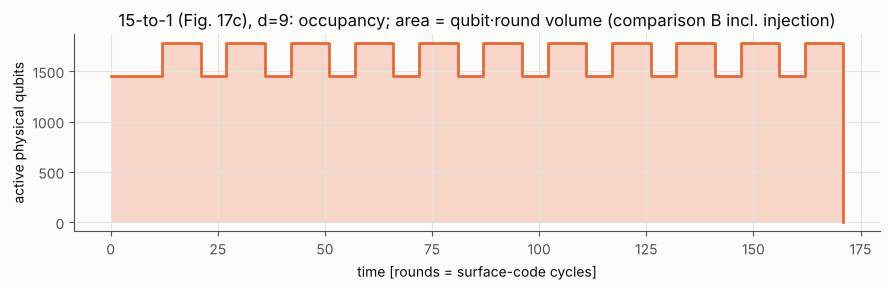

In [11]:
d_show = 9 if 9 in D_LIST else D_LIST[-1]
sel = stage_df[(stage_df.d == d_show) & (stage_df.model == 'FT_ref') & (stage_df.comparison == 'B') &
               (stage_df.level == 'physical') & (~stage_df.data_only) & (stage_df.gateset == 'primitive')]
t, xs, ys = 0, [], []
for _, r in sel.iterrows():
    xs += [t, t + r.rounds]; ys += [r.qubits, r.qubits]; t += r.rounds
fig, ax = plt.subplots(figsize=(9, 3))
ax.fill_between(xs, ys, step=None, color=C_LIT, alpha=0.25, lw=0)
ax.plot(xs, ys, color=C_LIT)
ax.set_xlabel('time [rounds = surface-code cycles]'); ax.set_ylabel('active physical qubits')
ax.set_title(f'15-to-1 (Fig. 17c), d={d_show}: occupancy; area = qubit·round volume (comparison B incl. injection)')
plt.tight_layout(); plt.savefig(f'{FIGURES}/msd_occupancy_timeline.png', dpi=150); plt.show()

## 6. 解釈と注意
* tile モデルは [Lit] の値（11 tiles, 11τ, $121d^3$）を再現する（検証ノートで確認）。
* 物理モデル（明示的構成）との差は $O(d)$ の下位項のみ。ただし $Z_m\otimes Y_0$ の twist 継ぎ目の検査（$O(d)$ 個）は未計上。
* **含めていない費用**：古典処理（デコード・測定結果に応じた基底選択）の時間、Fig. 18 の追加 2×2 ブロックによる注入の並列化（tile 数が増える代わりに注入待ちが消える）、$Z_m\otimes Y_0$ の twist 欠陥の詳細な安定化子配置。
* ノイズが無い場合は蒸留そのものが不要（理想入力 $|m\rangle$ がそのまま出力品質）であり、ここでの比較は**回路構造と資源の比較**である（§3.3 の限界）。